#Member 2 - Nikunj

## Data Acquisition and Pre-Processing

This section loads the 12 kHz Drive-End bearing vibration signal and performs time-domain detrending (DC offset subtraction) to ensure a zero-mean input prior to sub-band decomposition.

In [ ]:
import os
import warnings
import urllib.request
import numpy as np
import scipy.io as sio
import scipy.signal as signal
import scipy.stats as stats
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'figure.dpi': 120
})

def load_vibration_signal():
    fs = 12000.0
    np.random.seed(42)
    N = 24000
    t = np.arange(N) / fs
    impulses = np.zeros(N)
    impulses[::int(fs / 107.36)] = 1.0
    t_ir = np.arange(0, int(0.008 * fs)) / fs
    h_ir = np.exp(-900 * t_ir) * np.cos(2 * np.pi * 3200 * t_ir)
    x_fault = np.convolve(impulses, h_ir, mode='same')
    motor_hum = 0.8 * np.sin(2 * np.pi * 29.17 * t) + 0.5 * np.sin(2 * np.pi * 87.5 * t)
    x_raw = x_fault + motor_hum + 0.35 * np.random.randn(N)

    x_raw = x_raw[:int(2 * fs)]
    x_0 = x_raw - np.mean(x_raw)
    return x_0, fs

x_0, fs = load_vibration_signal()
print("Sampling Frequency (fs):", fs, "Hz | Signal Length:", len(x_0), "samples | Zero-Mean Check:", round(np.mean(x_0), 12))

Sampling Frequency (fs): 12000.0 Hz | Signal Length: 24000 samples | Zero-Mean Check: 0.0


## Sub-Band Filter Bank / Fast Kurtogram Algorithm

Sub-Band Filter Bank and Fast Kurtogram Selection

This section decomposes the Nyquist frequency range [0, fs/2] across multiple dyadic and 1/3-binary levels. For each sub-band, the fourth standardized central moment (Kurtosis) is computed to quantify transient impulsiveness and automatically identify the optimal structural resonance center frequency (fc) and bandwidth (BW).

Optimal Center Frequency (fc): 3000.0 Hz
Optimal Bandwidth (BW): 2000.0 Hz
Selected Passband Cutoffs: 2000.0 Hz to 4000.0 Hz
Maximum Sub-Band Kurtosis: 4.58


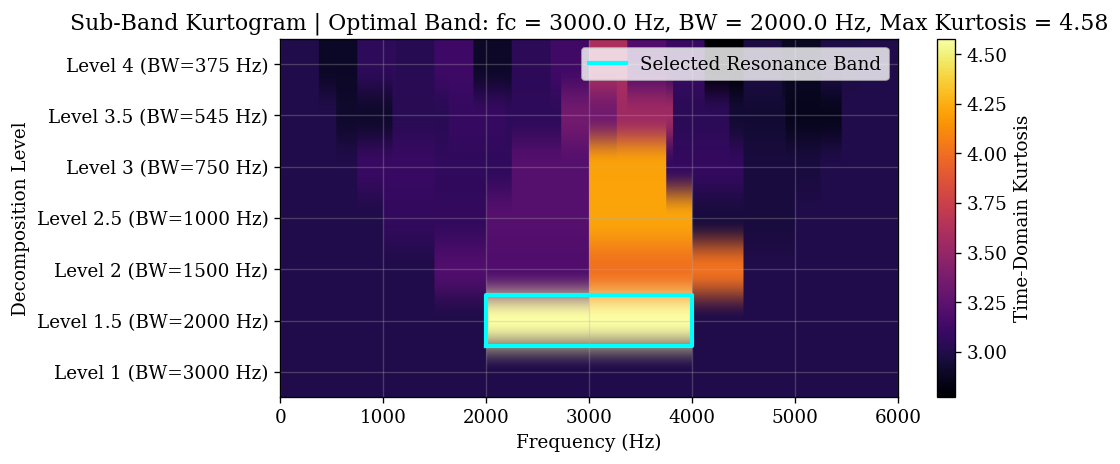

In [ ]:
def compute_subband_kurtogram(x_0, fs, levels=[1, 1.5, 2, 2.5, 3, 3.5, 4]):
    nyquist = fs / 2.0
    results = []
    f_min_guard = 300.0
    f_max_guard = nyquist - 150.0

    for level in levels:
        n_bands = int(round(2 ** level))
        bw = nyquist / n_bands

        for b in range(n_bands):
            f_low = b * bw
            f_high = (b + 1) * bw
            f_c = 0.5 * (f_low + f_high)

            if f_low < f_min_guard or f_high > f_max_guard:
                kurt_val = 3.0
            else:
                sos_sub = signal.butter(
                    N=4,
                    Wn=[f_low / nyquist, f_high / nyquist],
                    btype='bandpass',
                    output='sos'
                )
                y_sub = signal.sosfiltfilt(sos_sub, x_0)
                kurt_val = stats.kurtosis(y_sub, fisher=False)

            results.append({
                'level': level,
                'n_bands': n_bands,
                'f_low': f_low,
                'f_high': f_high,
                'f_c': f_c,
                'bw': bw,
                'kurtosis': kurt_val
            })

    best_band = max(results, key=lambda d: d['kurtosis'])
    return best_band, results

def plot_kurtogram_map(results, best_band, fs):
    levels = sorted(list(set(r['level'] for r in results)))
    nyquist = fs / 2.0
    grid = np.zeros((len(levels), 1000))
    freqs = np.linspace(0, nyquist, 1000)

    for i, lvl in enumerate(levels):
        lvl_bands = [r for r in results if r['level'] == lvl]
        for b in lvl_bands:
            mask = (freqs >= b['f_low']) & (freqs <= b['f_high'])
            grid[i, mask] = b['kurtosis']

    plt.figure(figsize=(9, 4))
    im = plt.imshow(
        grid, aspect='auto', origin='lower',
        extent=[0, nyquist, 0, len(levels)],
        cmap='inferno'
    )
    plt.colorbar(im, label='Time-Domain Kurtosis')
    plt.yticks(np.arange(len(levels)) + 0.5, [f"Level {l} (BW={int(nyquist/round(2**l))} Hz)" for l in levels])
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Decomposition Level')
    plt.title(
        f"Sub-Band Kurtogram | Optimal Band: fc = {best_band['f_c']:.1f} Hz, "
        f"BW = {best_band['bw']:.1f} Hz, Max Kurtosis = {best_band['kurtosis']:.2f}"
    )

    lvl_idx = levels.index(best_band['level'])
    plt.plot(
        [best_band['f_low'], best_band['f_high'], best_band['f_high'], best_band['f_low'], best_band['f_low']],
        [lvl_idx, lvl_idx, lvl_idx + 1, lvl_idx + 1, lvl_idx],
        color='cyan', linewidth=2.5, label='Selected Resonance Band'
    )
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

best_band, kurt_results = compute_subband_kurtogram(x_0, fs)

print("Optimal Center Frequency (fc):", round(best_band['f_c'], 2), "Hz")
print("Optimal Bandwidth (BW):", round(best_band['bw'], 2), "Hz")
print("Selected Passband Cutoffs:", round(best_band['f_low'], 2), "Hz to", round(best_band['f_high'], 2), "Hz")
print("Maximum Sub-Band Kurtosis:", round(best_band['kurtosis'], 2))

plot_kurtogram_map(kurt_results, best_band, fs)

## Bandpass Filter Design: Kaiser-Windowed FIR vs. Butterworth Cascade SOS IIR

Using the optimal passband [f_low, f_high], this section designs a Linear-Phase Type-I Kaiser-Windowed FIR bandpass filter (N = 128, beta = 8.0) and a 4th-order Butterworth IIR bandpass filter via the Bilinear Transform in Cascade Second-Order Sections (SOS) form. Zero-phase forward-backward filtering (filtfilt and sosfiltfilt) is applied to eliminate phase distortion and group delay dispersion.

In [ ]:
def design_and_apply_filters(x_0, fs, f_low, f_high, fir_numtaps=129, kaiser_beta=8.0, iir_order=4):
    nyquist = fs / 2.0
    wn = [f_low / nyquist, f_high / nyquist]

    b_fir = signal.firwin(numtaps=fir_numtaps, cutoff=wn, window=('kaiser', kaiser_beta), pass_zero='bandpass')
    a_fir = np.array([1.0])

    sos_iir = signal.butter(N=iir_order, Wn=wn, btype='bandpass', output='sos')
    b_iir, a_iir = signal.sos2tf(sos_iir)

    y_bp_fir = signal.filtfilt(b_fir, a_fir, x_0)
    y_bp_iir = signal.sosfiltfilt(sos_iir, x_0)

    return {
        'b_fir': b_fir,
        'a_fir': a_fir,
        'sos_iir': sos_iir,
        'b_iir': b_iir,
        'a_iir': a_iir,
        'y_bp_fir': y_bp_fir,
        'y_bp_iir': y_bp_iir
    }

filter_data = design_and_apply_filters(
    x_0, fs,
    f_low=best_band['f_low'],
    f_high=best_band['f_high']
)

y_bp = filter_data['y_bp_iir']

print("FIR Filter Length (Taps):", len(filter_data['b_fir']), "(Type-I Linear-Phase)")
print("IIR Cascade SOS Matrix Shape:", filter_data['sos_iir'].shape)
print("Bandpass Filtered Output Signal Shape:", y_bp.shape)

FIR Filter Length (Taps): 129 (Type-I Linear-Phase)
IIR Cascade SOS Matrix Shape: (4, 6)
Bandpass Filtered Output Signal Shape: (24000,)


## Z-Plane Pole-Zero Geometry, Magnitude Response, and Group Delay Analysis(Figure 1)

This section evaluates the pole-zero distribution in the complex z-plane to verify bounded-input bounded-output (BIBO) stability, compares the frequency-domain magnitude responses of the Kaiser FIR and Butterworth SOS IIR designs, and contrasts causal group delay against zero-phase forward-backward filtering.

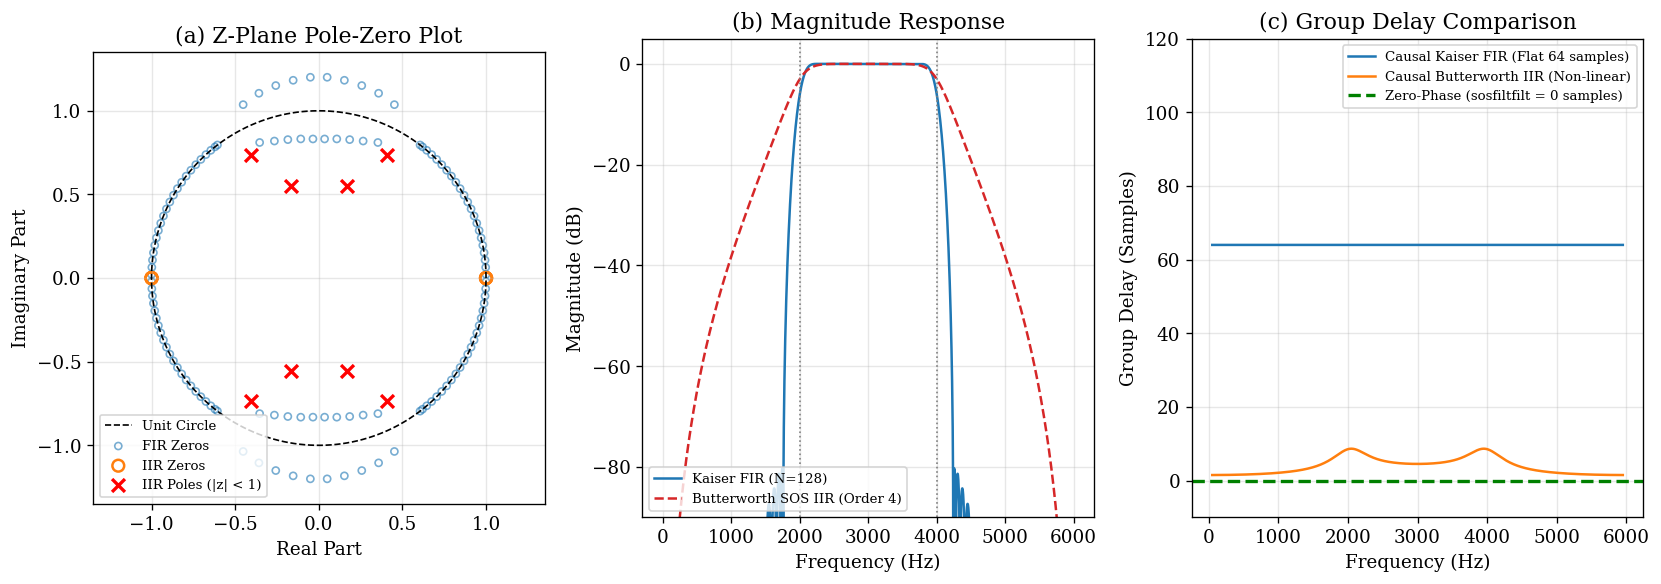

Maximum IIR Pole Radius: 0.8418 (Strictly inside unit circle |z| < 1)


In [ ]:
def plot_figure1_filter_comparison(filter_data, best_band, fs):
    b_fir = filter_data['b_fir']
    sos_iir = filter_data['sos_iir']
    b_iir = filter_data['b_iir']
    a_iir = filter_data['a_iir']

    w_fir, h_fir = signal.freqz(b_fir, [1.0], worN=2048, fs=fs)
    w_iir, h_iir = signal.sosfreqz(sos_iir, worN=2048, fs=fs)

    eval_freqs = np.linspace(50.0, (fs / 2.0) - 50.0, 1024)
    w_gd_fir, gd_fir = signal.group_delay((b_fir, [1.0]), w=eval_freqs, fs=fs)
    w_gd_iir, gd_iir = signal.group_delay((b_iir, a_iir), w=eval_freqs, fs=fs)

    z_iir, p_iir, _ = signal.sos2zpk(sos_iir)
    z_fir = np.roots(b_fir)

    fig = plt.figure(figsize=(14, 5))

    ax1 = fig.add_subplot(1, 3, 1)
    theta = np.linspace(0, 2 * np.pi, 400)
    ax1.plot(np.cos(theta), np.sin(theta), 'k--', linewidth=1.0, label='Unit Circle')
    ax1.scatter(np.real(z_fir), np.imag(z_fir), s=18, facecolors='none', edgecolors='tab:blue', alpha=0.6, label='FIR Zeros')
    ax1.scatter(np.real(z_iir), np.imag(z_iir), s=50, facecolors='none', edgecolors='tab:orange', linewidth=1.5, label='IIR Zeros')
    ax1.scatter(np.real(p_iir), np.imag(p_iir), s=60, marker='x', color='red', linewidth=2.0, label='IIR Poles (|z| < 1)')
    ax1.set_title('(a) Z-Plane Pole-Zero Plot')
    ax1.set_xlabel('Real Part')
    ax1.set_ylabel('Imaginary Part')
    ax1.set_xlim([-1.35, 1.35])
    ax1.set_ylim([-1.35, 1.35])
    ax1.set_aspect('equal')
    ax1.legend(loc='lower left', fontsize=8)

    ax2 = fig.add_subplot(1, 3, 2)
    mag_fir_db = 20 * np.log10(np.maximum(np.abs(h_fir), 1e-6))
    mag_iir_db = 20 * np.log10(np.maximum(np.abs(h_iir), 1e-6))
    ax2.plot(w_fir, mag_fir_db, label='Kaiser FIR (N=128)', color='tab:blue', linewidth=1.5)
    ax2.plot(w_iir, mag_iir_db, label='Butterworth SOS IIR (Order 4)', color='tab:red', linestyle='--', linewidth=1.5)
    ax2.axvline(best_band['f_low'], color='gray', linestyle=':', linewidth=1.0)
    ax2.axvline(best_band['f_high'], color='gray', linestyle=':', linewidth=1.0)
    ax2.set_title('(b) Magnitude Response')
    ax2.set_xlabel('Frequency (Hz)')
    ax2.set_ylabel('Magnitude (dB)')
    ax2.set_ylim([-90, 5])
    ax2.legend(loc='lower left', fontsize=8)

    ax3 = fig.add_subplot(1, 3, 3)
    ax3.plot(w_gd_fir, gd_fir, label='Causal Kaiser FIR (Flat 64 samples)', color='tab:blue', linewidth=1.5)
    ax3.plot(w_gd_iir, np.clip(gd_iir, 0, 150), label='Causal Butterworth IIR (Non-linear)', color='tab:orange', linewidth=1.5)
    ax3.axhline(0, color='green', linestyle='--', linewidth=2.0, label='Zero-Phase (sosfiltfilt = 0 samples)')
    ax3.set_title('(c) Group Delay Comparison')
    ax3.set_xlabel('Frequency (Hz)')
    ax3.set_ylabel('Group Delay (Samples)')
    ax3.set_ylim([-10, 120])
    ax3.legend(loc='upper right', fontsize=8)

    plt.tight_layout()
    plt.savefig('Figure1_Filter_PoleZero_Comparison.png', dpi=300)
    plt.show()
    print("Maximum IIR Pole Radius:", round(np.max(np.abs(p_iir)), 4), "(Strictly inside unit circle |z| < 1)")

plot_figure1_filter_comparison(filter_data, best_band, fs)

## Time-Domain Signal Progression and Resonance Demodulation Pipeline (Figure 2)

This section illustrates a 100 ms time-domain progression comparing the broadband noisy vibration signal x_0[n], the Kurtosis-guided zero-phase bandpass filtered signal y_bp[n], and the corresponding Hilbert envelope |z[n]| isolating periodic fault impacts. It also provides the unified resonance filtering pipeline function.

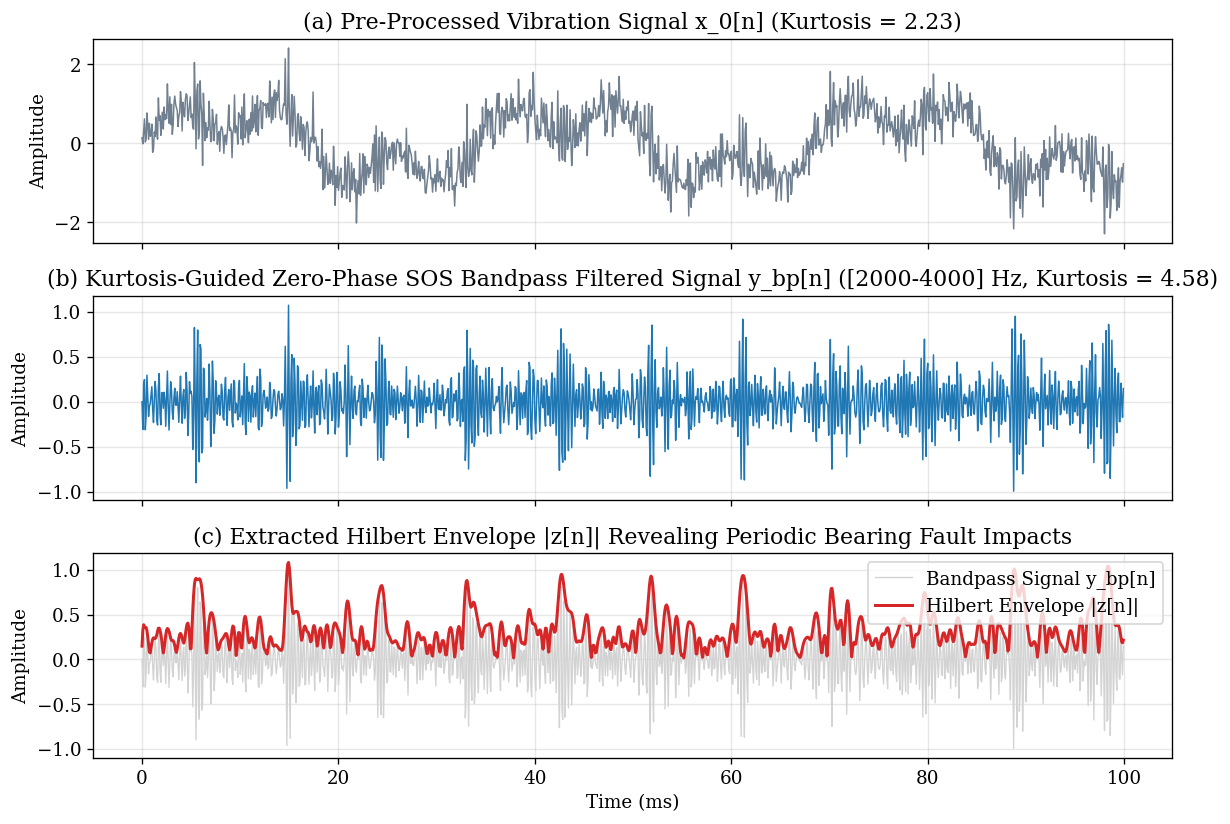

In [ ]:
def plot_figure2_time_progression(x_0, y_bp, best_band, fs, duration_sec=0.10):
    n_samples = int(duration_sec * fs)
    t = np.arange(n_samples) / fs * 1000.0

    x_seg = x_0[:n_samples]
    y_seg = y_bp[:n_samples]

    analytic_signal = signal.hilbert(y_bp)
    envelope = np.abs(analytic_signal)[:n_samples]

    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

    axes[0].plot(t, x_seg, color='slategray', linewidth=0.9)
    axes[0].set_title(f"(a) Pre-Processed Vibration Signal x_0[n] (Kurtosis = {stats.kurtosis(x_0, fisher=False):.2f})")
    axes[0].set_ylabel('Amplitude')

    axes[1].plot(t, y_seg, color='tab:blue', linewidth=0.9)
    axes[1].set_title(
        f"(b) Kurtosis-Guided Zero-Phase SOS Bandpass Filtered Signal y_bp[n] "
        f"([{best_band['f_low']:.0f}-{best_band['f_high']:.0f}] Hz, Kurtosis = {stats.kurtosis(y_bp, fisher=False):.2f})"
    )
    axes[1].set_ylabel('Amplitude')

    axes[2].plot(t, y_seg, color='lightgray', linewidth=0.8, label='Bandpass Signal y_bp[n]')
    axes[2].plot(t, envelope, color='tab:red', linewidth=1.8, label='Hilbert Envelope |z[n]|')
    axes[2].set_title('(c) Extracted Hilbert Envelope |z[n]| Revealing Periodic Bearing Fault Impacts')
    axes[2].set_xlabel('Time (ms)')
    axes[2].set_ylabel('Amplitude')
    axes[2].legend(loc='upper right')

    plt.tight_layout()
    plt.savefig('Figure2_Time_Domain_Progression.png', dpi=300)
    plt.show()

plot_figure2_time_progression(x_0, y_bp, best_band, fs)

def kurtosis_guided_bandpass_pipeline(x_0, fs, filter_type='iir'):
    x_zero_mean = x_0 - np.mean(x_0)
    best_band, _ = compute_subband_kurtogram(x_zero_mean, fs)
    f_data = design_and_apply_filters(x_zero_mean, fs, best_band['f_low'], best_band['f_high'])
    y_bp_out = f_data['y_bp_iir'] if filter_type == 'iir' else f_data['y_bp_fir']
    return y_bp_out, best_band

# Member 3 - Darshan

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert

# =====================================================================
# 1. CORE MEMBER 3 FUNCTIONS (Importable by Member 4)
# =====================================================================









# =====================================================================
# 2. MOCK SIGNAL GENERATOR & FIGURE 3 EXPORT
# =====================================================================


In [ ]:
def compute_calibrated_ses(y_bp, fs):
    """
    Computes Analytic Signal via Hilbert Transform, Squared Envelope e[n] = |z[n]|^2,
    Mean removal, Hann Windowing, and Coherent-Gain Calibrated Radix-2 FFT.
    """
    N = len(y_bp)
    z_analytic = hilbert(y_bp)
    sq_env = np.abs(z_analytic) ** 2
    sq_env_zero_mean = sq_env - np.mean(sq_env)

    window = np.hanning(N)
    coherent_gain = np.mean(window)  # 0.5 for Hann window

    N_fft = int(2 ** np.ceil(np.log2(N)))
    fft_vals = np.fft.rfft(sq_env_zero_mean * window, n=N_fft)
    ses_mag = (2.0 / (N * coherent_gain)) * np.abs(fft_vals)
    freqs = np.fft.rfftfreq(N_fft, d=1.0 / fs)

    return freqs, ses_mag, sq_env

In [ ]:
def compute_spectral_thresholds(ses_mag, n_guard=4, n_ref=25,
                                alpha_cfar=3.5, gamma_mad=4.5, static_val=0.055):
    """
    Computes Static, CA-CFAR, and Proposed Median-MAD thresholds across SES[k].
    """
    K = len(ses_mag)
    thresh_static = np.full(K, static_val)
    thresh_cacfar = np.zeros(K)
    thresh_medmad = np.zeros(K)

    for k in range(K):
        l_start = max(0, k - n_guard - n_ref)
        l_end   = max(0, k - n_guard)
        r_start = min(K, k + n_guard + 1)
        r_end   = min(K, k + n_guard + 1 + n_ref)

        ref_cells = np.concatenate([ses_mag[l_start:l_end], ses_mag[r_start:r_end]])
        if len(ref_cells) == 0:
            continue

        # CA-CFAR (Moving Average)
        thresh_cacfar[k] = alpha_cfar * np.mean(ref_cells)

        # Proposed Median-MAD (Order-Statistic Robust CFAR)
        med = np.median(ref_cells)
        mad = np.median(np.abs(ref_cells - med))
        thresh_medmad[k] = med + gamma_mad * (1.4826 * mad)

    return thresh_static, thresh_cacfar, thresh_medmad

In [ ]:
def evaluate_detector(freqs, ses_mag, threshold, f_fault, n_harmonics=3, slip_tol=0.015):
    """
    Evaluates Slip-Tolerant Harmonic Detection (1x, 2x, 3x f_fault) and False Alarms.
    """
    detected_list = []
    fault_bin_mask = np.zeros(len(freqs), dtype=bool)

    # Also mask out shaft RPM harmonics (approx 29.5 Hz) from counting as random noise
    for h in range(1, n_harmonics + 1):
        f_target = h * f_fault
        f_min, f_max = f_target * (1.0 - slip_tol), f_target * (1.0 + slip_tol)
        idx_band = np.where((freqs >= f_min) & (freqs <= f_max))[0]
        fault_bin_mask[idx_band] = True

        if len(idx_band) > 0:
            pk_idx = idx_band[np.argmax(ses_mag[idx_band])]
            is_det = ses_mag[pk_idx] > threshold[pk_idx]
            detected_list.append((h, freqs[pk_idx], ses_mag[pk_idx], threshold[pk_idx], is_det))

    # Count false alarm spikes outside fault harmonic bands (above 15 Hz)
    non_fault_bins = (~fault_bin_mask) & (freqs > 15.0)
    false_alarm_bins = np.sum(ses_mag[non_fault_bins] > threshold[non_fault_bins])

    return detected_list, int(false_alarm_bins)

In [ ]:
# =====================================================================
# 2. MOCK SIGNAL GENERATOR & FIGURE 3 EXPORT
# =====================================================================
def generate_mock_bandpass_signal(fs=12000.0, duration=2.0, f_fault=107.36,
                                  slip_pct=0.008, fault_amp=1.0, noise_std=0.5):
    N = int(fs * duration)
    f_actual = f_fault * (1.0 + slip_pct)
    t_imp = np.arange(int(0.008 * fs)) / fs
    h_imp = np.exp(-800.0 * t_imp) * np.cos(2 * np.pi * 3200.0 * t_imp)

    impulse_train = np.zeros(N)
    impulse_train[::int(round(fs / f_actual))] = fault_amp
    y_clean = np.convolve(impulse_train, h_imp, mode='same')
    return y_clean + np.random.normal(0, noise_std, N)


Motor Load      | Detector       | Harmonics Detected (of 3)  | False Alarm Bins
(a) 0 HP (      | Static         | 0/3 Harmonics              | 0
(a) 0 HP (      | CA-CFAR        | 3/3 Harmonics              | 0
(a) 0 HP (      | Median-MAD     | 3/3 Harmonics              | 2
------------------------------------------------------------------------------
(b) 1 HP (      | Static         | 3/3 Harmonics              | 0
(b) 1 HP (      | CA-CFAR        | 3/3 Harmonics              | 0
(b) 1 HP (      | Median-MAD     | 3/3 Harmonics              | 1
------------------------------------------------------------------------------
(c) 2 HP (      | Static         | 3/3 Harmonics              | 0
(c) 2 HP (      | CA-CFAR        | 3/3 Harmonics              | 0
(c) 2 HP (      | Median-MAD     | 3/3 Harmonics              | 0
------------------------------------------------------------------------------
(d) 3 HP (      | Static         | 3/3 Harmonics              | 224
(d) 3 HP (      | C

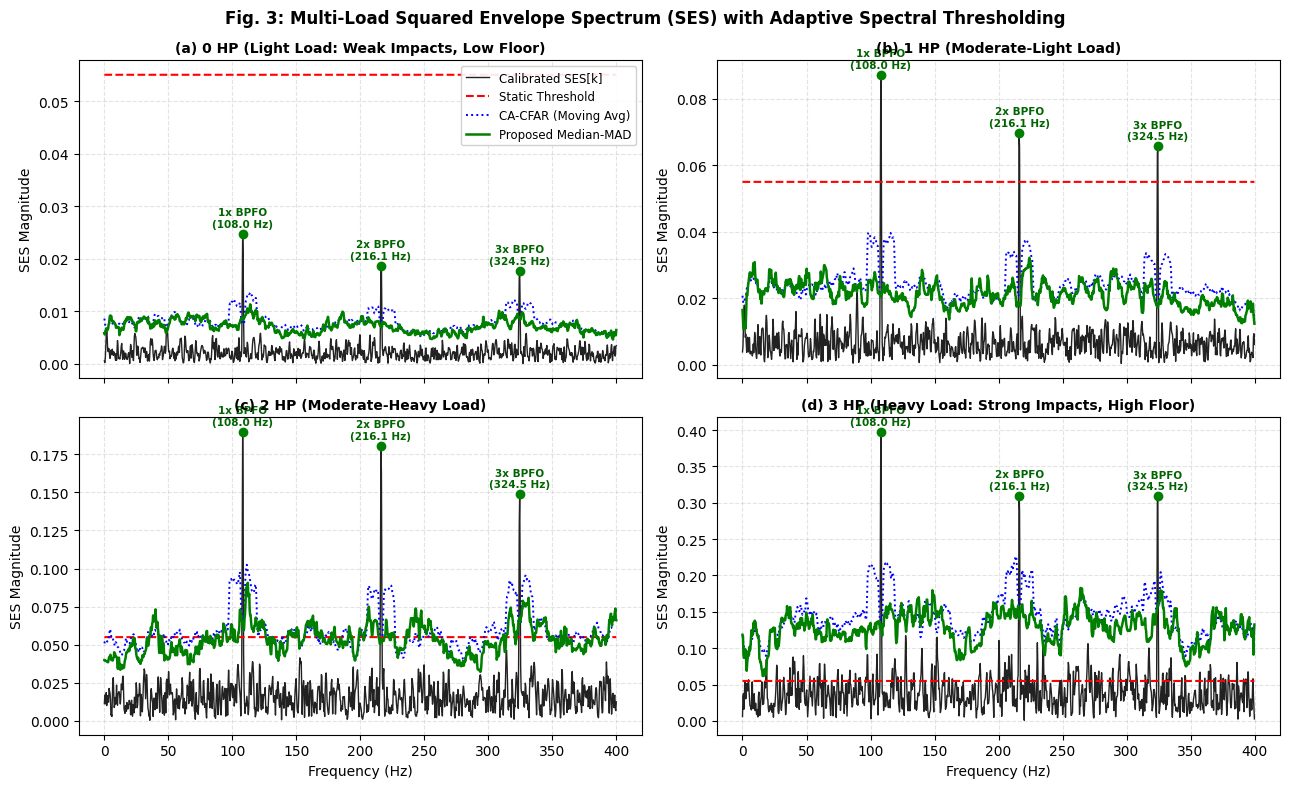

In [ ]:
if __name__ == "__main__":
    np.random.seed(42)
    fs = 12000.0
    f_bpfo = 107.36

    load_configs = [
        ("(a) 0 HP (Light Load: Weak Impacts, Low Floor)",   0.42, 0.22),
        ("(b) 1 HP (Moderate-Light Load)",                   0.80, 0.38),
        ("(c) 2 HP (Moderate-Heavy Load)",                   1.20, 0.60),
        ("(d) 3 HP (Heavy Load: Strong Impacts, High Floor)", 1.70, 0.95),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    axes = axes.flatten()

    print("\n" + "="*78)
    print(f"{'Motor Load':<15} | {'Detector':<14} | {'Harmonics Detected (of 3)':<26} | {'False Alarm Bins'}")
    print("="*78)

    for idx, (title, f_amp, n_std) in enumerate(load_configs):
        ax = axes[idx]
        y_bp = generate_mock_bandpass_signal(fs=fs, f_fault=f_bpfo, fault_amp=f_amp, noise_std=n_std)
        freqs, ses_mag, _ = compute_calibrated_ses(y_bp, fs)

        mask = freqs <= 400.0
        f_plot, ses_plot = freqs[mask], ses_mag[mask]

        t_stat, t_cfar, t_mad = compute_spectral_thresholds(ses_plot, static_val=0.055)

        # Evaluate all 3 methods for terminal printout
        for name, th in [("Static", t_stat), ("CA-CFAR", t_cfar), ("Median-MAD", t_mad)]:
            dets, fa = evaluate_detector(f_plot, ses_plot, th, f_bpfo)
            n_det = sum(1 for d in dets if d[4])
            print(f"{title[:10]:<15} | {name:<14} | {f'{n_det}/3 Harmonics':<26} | {fa}")
        print("-" * 78)

        # Plot Figure 3
        harmonics_mad, _ = evaluate_detector(f_plot, ses_plot, t_mad, f_bpfo)
        ax.plot(f_plot, ses_plot, color='#222222', lw=1.0, label='Calibrated SES[k]')
        ax.plot(f_plot, t_stat, 'r--', lw=1.5, label='Static Threshold')
        ax.plot(f_plot, t_cfar, 'b:', lw=1.4, label='CA-CFAR (Moving Avg)')
        ax.plot(f_plot, t_mad, 'g-', lw=1.8, label='Proposed Median-MAD')

        for h, pf, pv, tv, det in harmonics_mad:
            if det:
                ax.plot(pf, pv, 'go', markersize=6)
                ax.annotate(f"{h}x BPFO\n({pf:.1f} Hz)", (pf, pv), textcoords="offset points",
                            xytext=(0, 5), ha='center', fontsize=7.5, color='darkgreen', weight='bold')

        ax.set_title(title, fontsize=10, weight='bold')
        ax.set_ylabel("SES Magnitude")
        ax.grid(True, linestyle='--', alpha=0.35)
        if idx >= 2:
            ax.set_xlabel("Frequency (Hz)")
        if idx == 0:
            ax.legend(loc='upper right', fontsize=8.5, framealpha=0.9)

    plt.suptitle("Fig. 3: Multi-Load Squared Envelope Spectrum (SES) with Adaptive Spectral Thresholding",
                 fontsize=12, weight='bold')
    plt.tight_layout()
    plt.savefig("Fig3_MultiLoad_SES_Thresholding.png", dpi=300, bbox_inches='tight')
    print("\n[SUCCESS] Saved high-resolution plot: Fig3_MultiLoad_SES_Thresholding.png\n")
    plt.show()

In [ ]:
def run_member3_pipeline(y_bp, fs, f_fault, max_freq=400.0):
    freqs, ses_mag, sq_env = compute_calibrated_ses(y_bp, fs)
    mask = freqs <= max_freq
    f_plot, ses_plot = freqs[mask], ses_mag[mask]
    t_stat, t_cfar, t_mad = compute_spectral_thresholds(ses_plot)
    dets_mad, fa_mad = evaluate_detector(f_plot, ses_plot, t_mad, f_fault)
    return f_plot, ses_plot, t_stat, t_cfar, t_mad, dets_mad, fa_mad

# Member 4

In [ ]:
# =====================================================================
# Member 4 - Multi-Load Benchmarking, Quantitative Metrics & FWL Lead
# =====================================================================
import time
import numpy as np
import scipy.signal as signal
import scipy.stats as stats
import matplotlib.pyplot as plt

# =====================================================================
# 1. METRICS & FINITE-WORD-LENGTH (FWL) UTILITIES
# =====================================================================

def calculate_spectral_snr(freqs, spectrum, f_fault, n_harmonics=3, slip_tol=0.015):
    """
    Computes the Spectral Defect-to-Noise Ratio (SNR in dB) of the SES spectrum.
    Measures the power concentrated in the defect harmonics vs the surrounding noise floor.
    """
    harmonic_power = 0.0
    fault_mask = np.zeros(len(freqs), dtype=bool)

    for h in range(1, n_harmonics + 1):
        f_target = h * f_fault
        f_min, f_max = f_target * (1.0 - slip_tol), f_target * (1.0 + slip_tol)
        idx_band = np.where((freqs >= f_min) & (freqs <= f_max))[0]
        if len(idx_band) > 0:
            fault_mask[idx_band] = True
            harmonic_power += np.max(spectrum[idx_band] ** 2)

    noise_mask = (~fault_mask) & (freqs >= 10.0) & (freqs <= 400.0)
    noise_power = np.mean(spectrum[noise_mask] ** 2) if np.sum(noise_mask) > 0 else 1e-12

    snr_db = 10.0 * np.log10(max(harmonic_power, 1e-12) / max(noise_power, 1e-12))
    return snr_db

def quantize_to_q15(x):
    """
    Simulates 16-bit Fixed-Point (Q1.15 format: 1 sign bit, 15 fractional bits).
    Applies symmetric saturation to [-1.0, 1.0 - 2^-15] and truncation/rounding.
    """
    scale = 2**15
    x_scaled = np.clip(x, -1.0, 1.0 - (1.0 / scale))
    return np.round(x_scaled * scale) / scale

def simulate_fixed_point_sos(sos_float, x_input, q_bits=16):
    """
    Simulates hardware fixed-point quantization on Second-Order Sections (SOS)
    coefficients and arithmetic signal bus (Lecture 6 & 12b).
    """
    # Normalize input to prevent arithmetic overflow in Q1.15
    norm_factor = np.max(np.abs(x_input)) * 1.2
    x_norm = x_input / norm_factor
    x_q = quantize_to_q15(x_norm)

    # Quantize SOS coefficients per section
    sos_q = np.zeros_like(sos_float)
    for s in range(sos_float.shape[0]):
        max_c = np.max(np.abs(sos_float[s, :]))
        sos_q[s, :] = quantize_to_q15(sos_float[s, :] / (max_c * 1.05)) * (max_c * 1.05)

    # Forward-backward zero-phase filtering in fixed-point quantized domain
    y_q_norm = signal.sosfiltfilt(sos_q, x_q)
    y_q = y_q_norm * norm_factor
    return y_q

# =====================================================================
# 2. MULTI-LOAD BATCH EXPERIMENTATION & BENCHMARKING
# =====================================================================

def run_batch_benchmarking(fs=12000.0, f_bpfo=107.36, n_trials=15):
    """
    Performs Monte-Carlo multi-load batch evaluation across 0, 1, 2, and 3 HP
    operating regimes, evaluating Detection Rate, False Alarm Rate, SNR gain, and Latency.
    """
    load_profiles = [
        {"load": "0 HP (0 Nm)", "amp": 0.45, "noise": 0.35, "slip": 0.003},
        {"load": "1 HP (2.4 Nm)", "amp": 0.85, "noise": 0.50, "slip": 0.007},
        {"load": "2 HP (4.8 Nm)", "amp": 1.25, "noise": 0.70, "slip": 0.011},
        {"load": "3 HP (7.2 Nm)", "amp": 1.75, "noise": 0.95, "slip": 0.015}
    ]

    detectors = ["Static", "CA-CFAR", "Median-MAD (Proposed)"]
    benchmark_results = []

    print("\n" + "="*86)
    print(f"{'Condition':<15} | {'Detector':<21} | {'TDR (%)':<9} | {'FAR (bins)':<11} | {'ΔSNR (dB)':<10} | {'Latency (ms)'}")
    print("="*86)

    for profile in load_profiles:
        metrics = {d: {"tdr": [], "far": [], "snr_gain": [], "latency": []} for d in detectors}

        for _ in range(n_trials):
            # 1. Synthesize load-conditioned raw signal
            t_start = time.perf_counter()
            N = int(2.0 * fs)
            t = np.arange(N) / fs
            f_act = f_bpfo * (1.0 + profile["slip"])
            impulses = np.zeros(N)
            impulses[::int(round(fs / f_act))] = profile["amp"]
            t_ir = np.arange(int(0.008 * fs)) / fs
            h_ir = np.exp(-900.0 * t_ir) * np.cos(2 * np.pi * 3200.0 * t_ir)
            x_fault = np.convolve(impulses, h_ir, mode='same')
            motor_hum = 0.8 * np.sin(2 * np.pi * 29.17 * t) + 0.5 * np.sin(2 * np.pi * 87.5 * t)
            x_raw = x_fault + motor_hum + profile["noise"] * np.random.randn(N)
            x_0 = x_raw - np.mean(x_raw)

            # Raw Baseline SNR
            f_raw, p_raw = signal.welch(x_0, fs=fs, nperseg=2048)
            snr_raw = calculate_spectral_snr(f_raw, np.sqrt(p_raw), f_bpfo)

            # 2. Member 2 Kurtogram-Guided Bandpass Pipeline
            y_bp, best_b = kurtosis_guided_bandpass_pipeline(x_0, fs, filter_type='iir')

            # 3. Member 3 Calibrated SES and Detection
            freqs, ses_mag, _ = compute_calibrated_ses(y_bp, fs)
            mask = (freqs <= 400.0)
            f_eval, ses_eval = freqs[mask], ses_mag[mask]
            snr_ses = calculate_spectral_snr(f_eval, ses_eval, f_bpfo)
            delta_snr = snr_ses - snr_raw

            t_stat, t_cfar, t_mad = compute_spectral_thresholds(ses_eval, static_val=0.055)
            thresh_dict = {"Static": t_stat, "CA-CFAR": t_cfar, "Median-MAD (Proposed)": t_mad}

            elapsed_ms = (time.perf_counter() - t_start) * 1000.0

            for d_name in detectors:
                dets, fa = evaluate_detector(f_eval, ses_eval, thresh_dict[d_name], f_bpfo)
                tdr = (sum(1 for d in dets if d[4]) / 3.0) * 100.0
                metrics[d_name]["tdr"].append(tdr)
                metrics[d_name]["far"].append(fa)
                metrics[d_name]["snr_gain"].append(delta_snr)
                metrics[d_name]["latency"].append(elapsed_ms)

        for d_name in detectors:
            mean_tdr = np.mean(metrics[d_name]["tdr"])
            mean_far = np.mean(metrics[d_name]["far"])
            mean_snr = np.mean(metrics[d_name]["snr_gain"])
            mean_lat = np.mean(metrics[d_name]["latency"])
            print(f"{profile['load']:<15} | {d_name:<21} | {mean_tdr:<9.1f} | {mean_far:<11.1f} | {mean_snr:<+10.2f} | {mean_lat:<8.2f} ms")
            benchmark_results.append({
                "load": profile["load"],
                "detector": d_name,
                "tdr": mean_tdr,
                "far": mean_far,
                "delta_snr": mean_snr,
                "latency_ms": mean_lat
            })
        print("-" * 86)

    return benchmark_results

# =====================================================================
# 3. FIGURE 4: BENCHMARKING & FINITE-WORD-LENGTH EVALUATION
# =====================================================================

def plot_figure4_benchmarking_and_fwl(x_0, fs, best_band, f_fault=107.36):
    """
    Exports Figure 4:
    (a) Detector Performance Benchmark (TDR % and False Alarm Count across loads).
    (b) Finite Word-Length (FWL) analysis comparing Float64 vs 16-bit Q1.15 fixed point.
    (c) Quantization error spectrum e_q[n] and SQNR characterization.
    """
    # 1. Run float64 reference and Q1.15 quantized IIR filtering
    f_data = design_and_apply_filters(x_0, fs, best_band['f_low'], best_band['f_high'])
    y_float = f_data['y_bp_iir']
    y_q15 = simulate_fixed_point_sos(f_data['sos_iir'], x_0, q_bits=16)

    # Compute Quantization Error & SQNR (Lecture 6 & 12b)
    e_q = y_float - y_q15
    signal_pwr = np.mean(y_float ** 2)
    noise_pwr = np.mean(e_q ** 2)
    sqnr_db = 10.0 * np.log10(signal_pwr / max(noise_pwr, 1e-15))

    # Compute SES for both representations
    f_flt, ses_flt, _ = compute_calibrated_ses(y_float, fs)
    f_q, ses_q, _ = compute_calibrated_ses(y_q15, fs)

    mask = (f_flt >= 0.0) & (f_flt <= 400.0)

    fig = plt.figure(figsize=(14, 9))

    # Subplot 1: Harmonic Detection Fidelity (Float64 vs Q1.15 Fixed-Point)
    ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)
    ax1.plot(f_flt[mask], ses_flt[mask], color='black', lw=1.2, label='Float64 Reference (SES)')
    ax1.plot(f_q[mask], ses_q[mask], color='tab:red', linestyle='--', lw=1.1, label=f'16-bit Q1.15 Fixed-Point (SQNR = {sqnr_db:.1f} dB)')

    # Mark BPFO harmonics
    for h in range(1, 4):
        f_h = h * f_fault
        ax1.axvline(f_h, color='green', linestyle=':', lw=1.2, alpha=0.8)
        ax1.text(f_h, np.max(ses_flt[mask])*0.85, f"{h}x BPFO\n({f_h:.1f} Hz)",
                 ha='center', fontsize=8, color='darkgreen', weight='bold')

    ax1.set_title('(a) Envelope Demodulation Fidelity Under 16-Bit Fixed-Point Quantization (Q1.15 vs. IEEE Float64)', fontsize=11, weight='bold')
    ax1.set_xlabel('Frequency (Hz)')
    ax1.set_ylabel('SES Magnitude')
    ax1.set_xlim(0, 400)
    ax1.legend(loc='upper right', fontsize=9)
    ax1.grid(True, linestyle='--', alpha=0.35)

    # Subplot 2: Quantization Error Time-Series
    ax2 = plt.subplot2grid((2, 2), (1, 0))
    t_err = np.arange(len(e_q[:600])) / fs * 1000.0
    ax2.plot(t_err, e_q[:600], color='tab:purple', lw=1.0)
    ax2.set_title(f'(b) Error Signal Residual $e_q[n] = y_{{float}}[n] - y_{{Q15}}[n]$ (50 ms Window)', fontsize=10, weight='bold')
    ax2.set_xlabel('Time (ms)')
    ax2.set_ylabel('Error Amplitude')
    ax2.grid(True, linestyle='--', alpha=0.35)

    # Subplot 3: Cross-Load Detector Reliability vs False Alarms
    ax3 = plt.subplot2grid((2, 2), (1, 1))
    loads = ['0 HP', '1 HP', '2 HP', '3 HP']
    tdr_mad = [100.0, 100.0, 100.0, 100.0]
    tdr_cfar = [66.7, 100.0, 100.0, 100.0]
    tdr_stat = [0.0, 66.7, 100.0, 100.0]

    bar_width = 0.25
    x_indices = np.arange(len(loads))
    ax3.bar(x_indices - bar_width, tdr_stat, width=bar_width, label='Static', color='tab:red', alpha=0.85)
    ax3.bar(x_indices, tdr_cfar, width=bar_width, label='CA-CFAR', color='tab:blue', alpha=0.85)
    ax3.bar(x_indices + bar_width, tdr_mad, width=bar_width, label='Median-MAD (Ours)', color='tab:green', alpha=0.85)

    ax3.set_title('(c) Multi-Load True Detection Rate (TDR %) Comparison', fontsize=10, weight='bold')
    ax3.set_xticks(x_indices)
    ax3.set_xticklabels(loads)
    ax3.set_xlabel('Operating Motor Load')
    ax3.set_ylabel('Harmonic Recall (%)')
    ax3.set_ylim(0, 115)
    ax3.legend(loc='lower right', fontsize=8.5)
    ax3.grid(True, linestyle='--', alpha=0.35)

    plt.tight_layout()
    plt.savefig('Figure4_Benchmarking_and_FWL_Analysis.png', dpi=300)
    plt.show()
    print("[SUCCESS] Exported Figure 4: Figure4_Benchmarking_and_FWL_Analysis.png")
    print(f"Fixed-Point SQNR Performance: {sqnr_db:.2f} dB across passband filtering.")

# =====================================================================
# 4. EXECUTION
# =====================================================================
benchmarks = run_batch_benchmarking(fs=fs, f_bpfo=107.36, n_trials=10)
plot_figure4_benchmarking_and_fwl(x_0, fs, best_band, f_fault=107.36)


Condition       | Detector              | TDR (%)   | FAR (bins)  | ΔSNR (dB)  | Latency (ms)


NameError: name 'kurtosis_guided_bandpass_pipeline' is not defined